## Initial Spinup Analysis: 
Comparison of model output to forcing to ensure everything is working as expected.

Since the analysis here is monthly, I don't need to worry about Gregorian/Julian calendar conversions.

In [1]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import os

In [2]:
# Run configuration
snotel_site = 'Tony Grove RS'  #Use the Snotel name
spin_up = '50y'
forcings = 's00000000'
forcing_version = 'v0.4.4'  # Version of the forcing data
spinup_version = 'v1.0debug'
spinup_build_version = 'V0.1'
path_env = 'desktop' # 'desktop' or 'alpine'

In [3]:
# Configure environment
if path_env == 'desktop':
    output_path = 'C:/Users/clmbn/NMT_PhD/data/output' #desktop
    snotel_path = 'C:/Users/clmbn/NMT_PhD/data/snotel/' #desktop
    forcing_path = 'C:/Users/clmbn/NMT_PhD/data/forcing/' #desktop
elif path_env == 'alpine':
    output_path = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    snotel_path = r'/projects/ccox1@xsede.org/data/snotel/'
    forcing_path = r'/projects/ccox1@xsede.org/data/forcing/'
else:
    raise ValueError("Invalid path_env. Choose 'desktop' or 'alpine'.")

In [4]:
# Convert name for output paths
site = snotel_site.replace(' ','').lower()
print(f'Output site: {site}')

Output site: tonygrovers


Load forcing:
Forcing is 10 years of NLDAS data that is then looped for the spinup period.

In [10]:
forcing_10yr = xr.open_dataset(os.path.join(forcing_path, site, f'{site}_spinup{spinup_build_version}_s00000000_{forcing_version}.nc'))

In [ ]:
forcing_10yr

In [6]:
def get_spinup_forcing(forcing_ds: xr.Dataset, var_name: str) -> pd.Series:
    '''
    Extract a given variable (at a daily timestep) from the forcing dataset and loop it for the 100 year spinup period.
    Return a pandas Series with the looped data.
    '''
    # If 'precip' get sum of 'Rainf' and 'Snowf'
    if var_name == 'precip':
        forcing_ds = forcing_ds.assign(precip=forcing_ds['Rainf'] + forcing_ds['Snowf'])
    
    # Extract the variable data
    data = forcing_ds[var_name].isel(latitude=0, longitude=0).to_series()

    # Resample to daily frequency
    data_daily = data.resample('D').mean()

    # Loop the data for the spinup period
    # The model uses an interpolation algorithm to do the looping, but concatenating the data is sufficient for this purpose.
    # I need to leave off the last day of the data when concatenating because the spinup start and end on the same day.
    spinup_years = int(spin_up[:-1])  # Extract the number of years from the spin_up string
    looped = pd.concat([data_daily[:-1]] * int(spinup_years / 10), ignore_index=True)

    # Generate a new index that starts at the first day of the model run
    model_start_year = data_daily.index[-1].year - spinup_years
    model_start = data_daily.index[0].replace(year=model_start_year)
    looped.index = pd.date_range(start=model_start, periods=len(looped), freq='D')

    # Create date range accounting for Julian 1900 leap year if necessary
    # if model_start < pd.Timestamp('1900-03-01'):
    #     model_end = data_daily.index[-1] + pd.Timedelta(days=1)  # Add on a day to account for the leap year in 1900
    # else:
    #     model_end = data_daily.index[-1]
    # model_index = pd.date_range(start=model_start, end=model_end, freq='D')

    # Shift index by 12 hours to match model output
    looped.index = looped.index + pd.Timedelta(hours=12)

    looped.name = var_name

    return looped
    


Load diagnostics

In [7]:
output_folder = os.path.join(output_path,f'{site}/{site}_spinup_{spin_up}_{forcings}_{spinup_version}/history/')

In [8]:
# Find the land month file name in folder and open
land_month=None
for filename in os.listdir(output_folder):
    if filename.endswith(".land_month.nc"):
        land_month = xr.open_dataset(output_folder + filename)
if not land_month:
    print('Error: no land daily found')

In [18]:
# Create a dataframe whose index is the name of the variable and the columns are: dimensions, long_name, units
land_vars_df = pd.DataFrame({
    'dimensions': [land_month[var].dims for var in land_month.data_vars],
    'long_name': [land_month[var].attrs.get('long_name', '') for var in land_month.data_vars],
    'units': [land_month[var].attrs.get('units', '') for var in land_month.data_vars]
}, index=land_month.data_vars)

In [ ]:
land_month

### Analysis: SW Radiation

In [11]:
forcing_SWdown = get_spinup_forcing(forcing_10yr, 'SWdown')
forcing_SWdown_month = forcing_SWdown.resample('MS').mean()

# Shift index forward 15 days to match the land month data
forcing_SWdown_month.index = forcing_SWdown_month.index + pd.DateOffset(days=15)

In [12]:
# Extract SW radiation components from land_daily
swdn_dir = land_month['swdn_dir'].isel(grid_index=0).to_dataframe()
swdn_dir = swdn_dir.reset_index().pivot(index='time', columns='band', values='swdn_dir')

swdn_diff = land_month['swdn_dif'].isel(grid_index=0).to_dataframe()
swdn_diff = swdn_diff.reset_index().pivot(index='time', columns='band', values='swdn_dif')

# Combine the direct and diffuse components
swdn_combined = pd.merge(swdn_dir, swdn_diff, left_index=True, right_index=True, suffixes=('_dir', '_dif'))

# Test
swdn_combined.head()

band,1.0_dir,2.0_dir,1.0_dif,2.0_dif
time,,,,
1960-01-16 12:00:00,24.192266,32.068817,14.827518,19.655083
1960-02-15 12:00:00,33.972485,45.033295,20.821846,27.601051
1960-03-16 12:00:00,51.185108,67.850029,31.371517,41.585499
1960-04-16 00:00:00,68.143433,90.329674,41.765331,55.363346
1960-05-16 12:00:00,77.543259,102.789902,47.526512,63.000263


In [13]:
swdn_combined['swdn_total'] = swdn_combined.sum(axis=1)

In [14]:
swdn_combined.index

Index([1960-01-16 12:00:00, 1960-02-15 12:00:00, 1960-03-16 12:00:00,
       1960-04-16 00:00:00, 1960-05-16 12:00:00, 1960-06-16 00:00:00,
       1960-07-16 12:00:00, 1960-08-16 12:00:00, 1960-09-16 00:00:00,
       1960-10-16 12:00:00,
       ...
       1979-03-16 12:00:00, 1979-04-16 00:00:00, 1979-05-16 12:00:00,
       1979-06-16 00:00:00, 1979-07-16 12:00:00, 1979-08-16 12:00:00,
       1979-09-16 00:00:00, 1979-10-16 12:00:00, 1979-11-16 00:00:00,
       1979-12-16 12:00:00],
      dtype='object', name='time', length=240)

In [15]:
swdn_combined.index = pd.to_datetime([pd.Timestamp(x.strftime('%Y-%m-%d %H:%M:%S')) for x in swdn_combined.index])

Text(0.5, 1.0, 'SW Radiation Comparison')

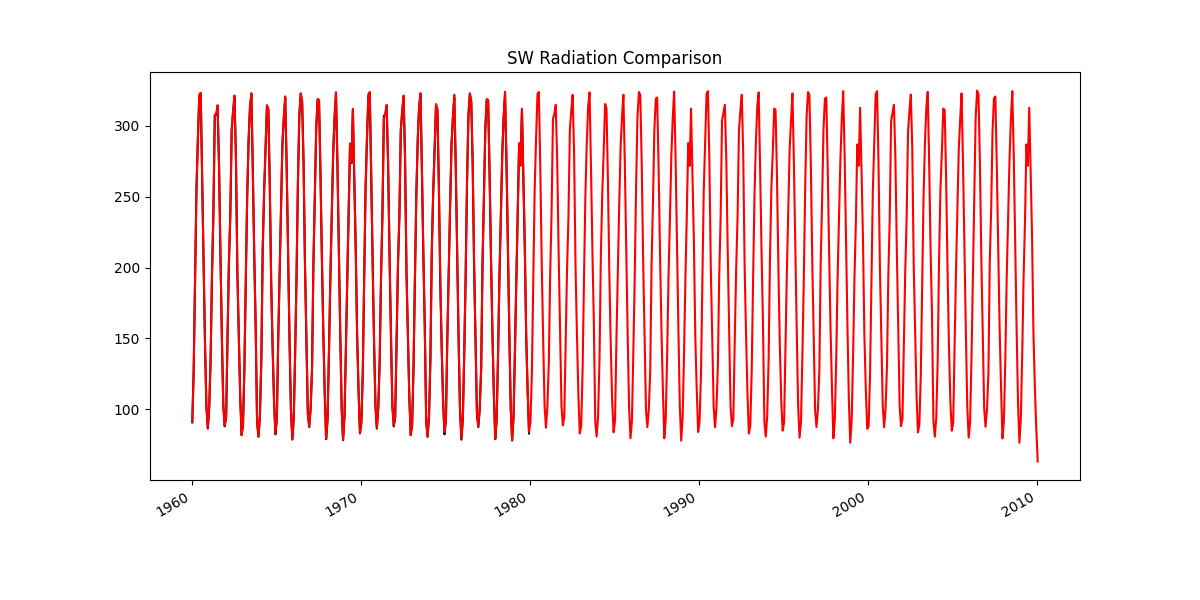

In [17]:
# Plotting the SW radiation components
plt.figure(figsize=(12, 6))
swdn_combined['swdn_total'].plot(label='Total SW Radiation', color='black')
forcing_SWdown_month.plot(label='Forcing SW Radiation', color='red')
plt.title('SW Radiation Comparison')

### Analysis: Vegetation

In [19]:
vegetation_data = land_month[['snow_depth','precip','Tgrnd','height','lai']].isel(grid_index=0).to_dataframe()
vegetation_data.index = vegetation_data.index.to_datetimeindex()

# Drop all extraneous columns
vegetation_data = vegetation_data[['snow_depth','precip','Tgrnd','height','lai']]

C:\Users\clmbn\AppData\Local\Temp\ipykernel_12228\2135545976.py:2: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  vegetation_data.index = vegetation_data.index.to_datetimeindex()


Compare precip to verify that the forcing is correct.

In [20]:
forcing_precip = get_spinup_forcing(forcing_10yr, 'precip')
forcing_precip_month = forcing_precip.resample('MS').mean()

# Shift index forward 15 days to match the land month data
forcing_precip_month.index = forcing_precip_month.index + pd.DateOffset(days=15)

<Axes: >

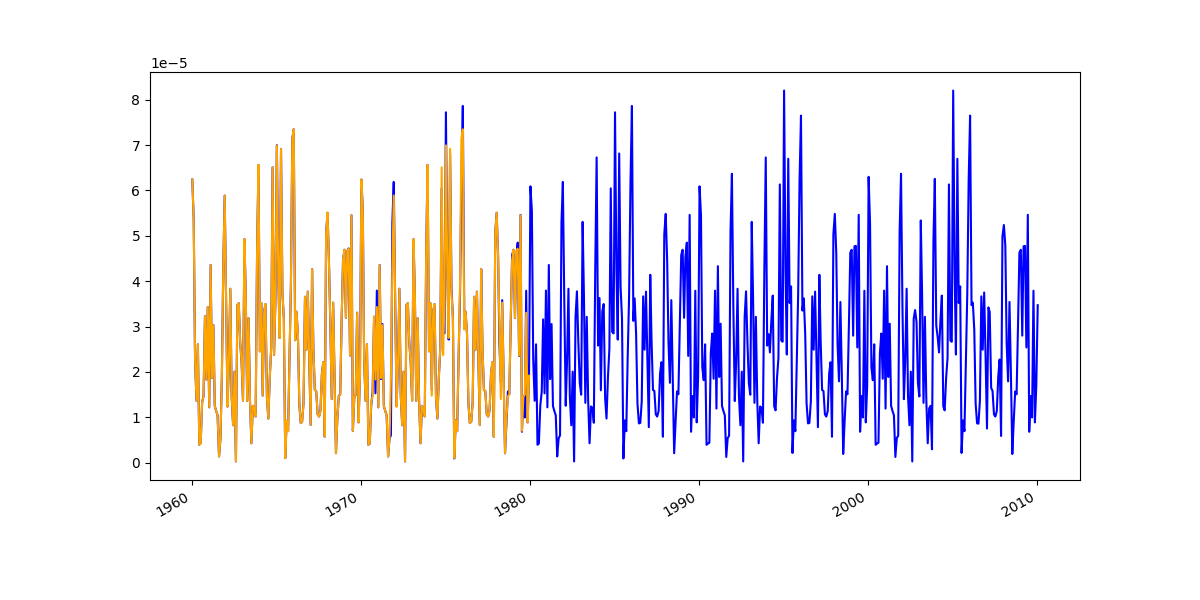

In [21]:
# Plot precip datasets on the same plot
fig, ax = plt.subplots(figsize=(12, 6))
forcing_precip_month.plot(ax=ax, label='Forcing Precipitation', color='blue')
vegetation_data['precip'].plot(ax=ax, label='Vegetation Precipitation', color='orange')

The two datasets should basically be the same, although the land_month data might be averaged differently with a julian calendar. At least they are quite similar.

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object)

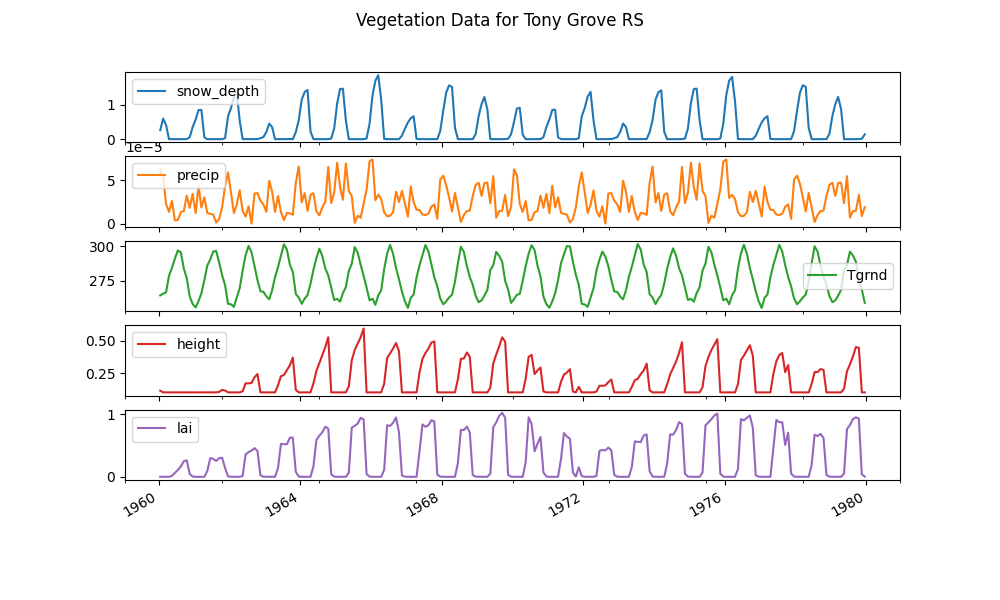

In [22]:
vegetation_data.plot(subplots=True, figsize=(10, 6), title='Vegetation Data for ' + snotel_site)

### Analysis: Soil

In [23]:
# Function for extracting soil data
def extract_soil_data(soil_var) -> pd.DataFrame:
    soil_data = land_month[[soil_var]].isel(grid_index=0).to_dataframe()
    soil_data_df = soil_data.reset_index().pivot(index='time', columns='zfull_soil', values=soil_var)
    soil_data_df.columns.name = 'Depth'
    soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex()
    soil_data_df.columns = [f"{col:03.2f}" for col in soil_data_df.columns]
    return soil_data_df

In [24]:
# Extract the soil data at different depths
soil_T = extract_soil_data('soil_T')
soil_liq = extract_soil_data('soil_liq')
soil_ice = extract_soil_data('soil_ice')

C:\Users\clmbn\AppData\Local\Temp\ipykernel_12228\2036034610.py:6: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex()
C:\Users\clmbn\AppData\Local\Temp\ipykernel_12228\2036034610.py:6: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex()
C:\Users\clmbn\AppData\Local\Temp\ipykernel_12228\2036034610.py:6: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which us

In [25]:
# Get air temperature from forcing data
Tair = get_spinup_forcing(forcing_10yr, 'Tair')
Tair_month = Tair.resample('MS').mean()

# Shift index forward 15 days to match the land month data
Tair_month.index = Tair_month.index + pd.DateOffset(days=15)

In [26]:
# Merge in ground surface temperature and air temperature
soil_T['Tgrnd'] = vegetation_data['Tgrnd']
#soil_T['Tair'] = Tair_month.to_numpy()

# Change soil_T values from Kelvin to Celsius
soil_T = soil_T - 273.15

# Add snow depth to soil_T dataframe
soil_T['snow_depth'] = vegetation_data['snow_depth']

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object)

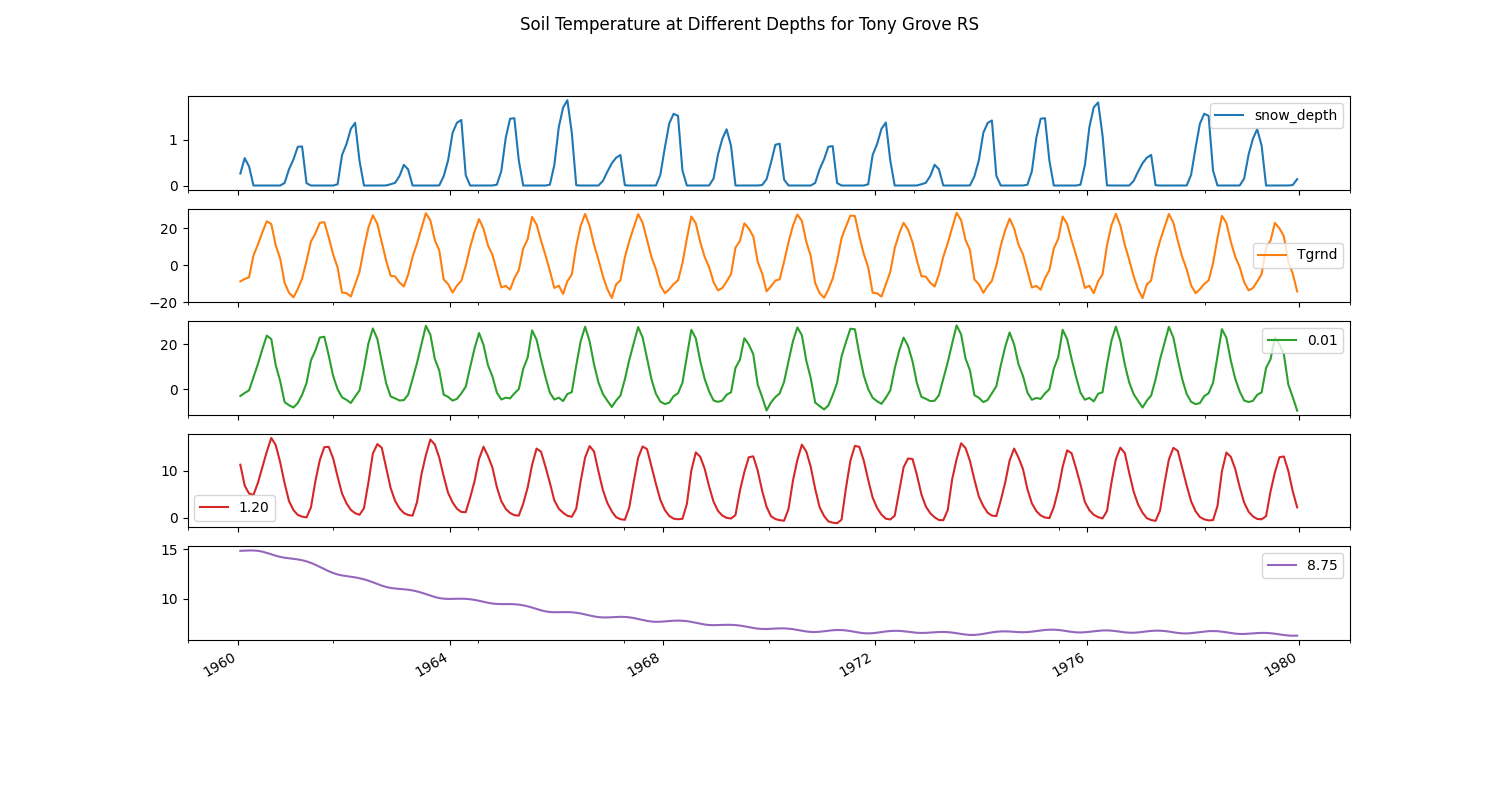

In [27]:
soil_T[['snow_depth','Tgrnd','0.01','1.20','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Temperature at Different Depths for ' + snotel_site)

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
      dtype=object)

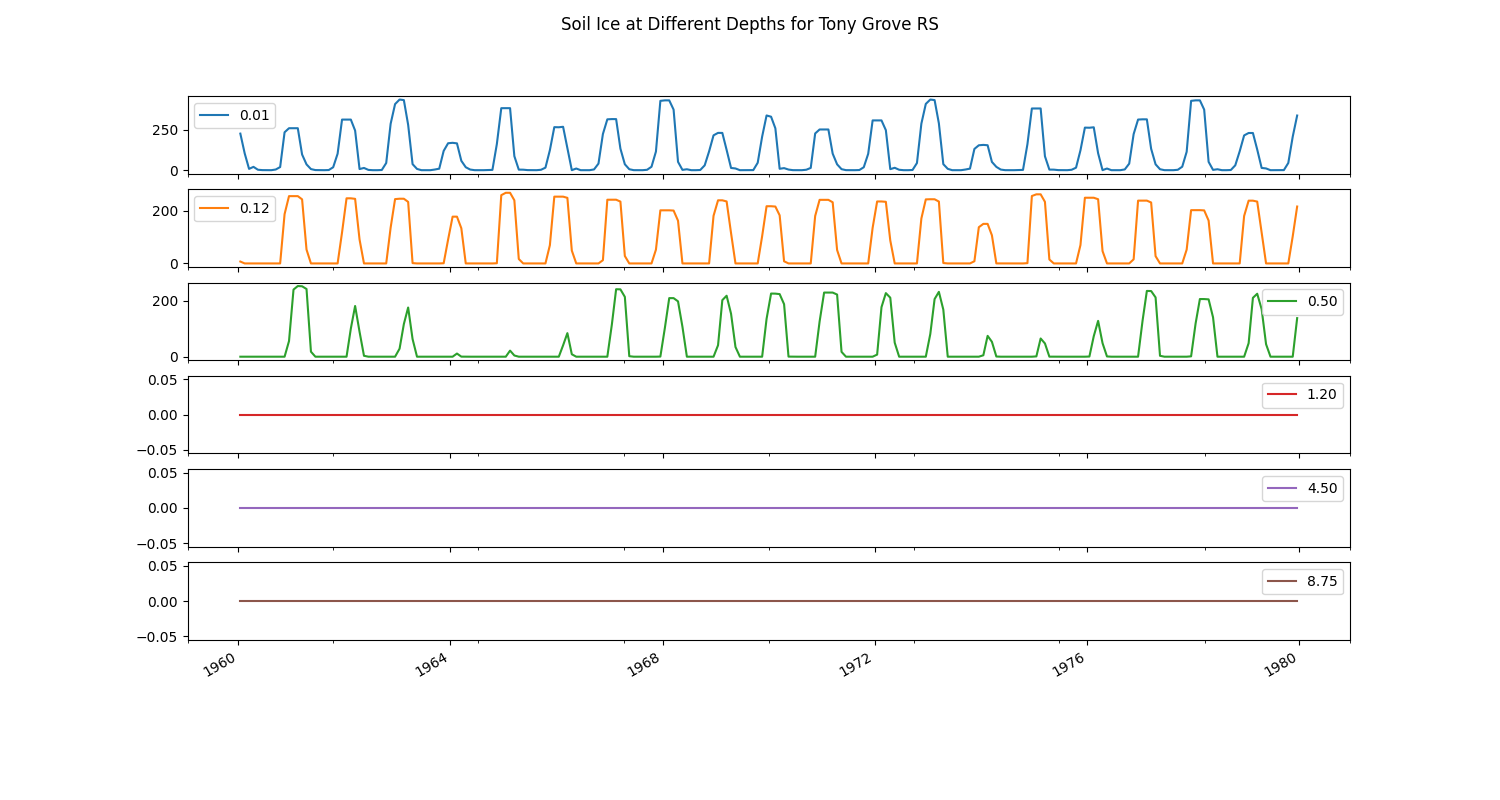

In [28]:
soil_ice[['0.01','0.12','0.50','1.20','4.50','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Ice at Different Depths for ' + snotel_site)

In [29]:
# Add precip to soil_liq dataframe
soil_liq['precip'] = vegetation_data['precip']

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >], dtype=object)

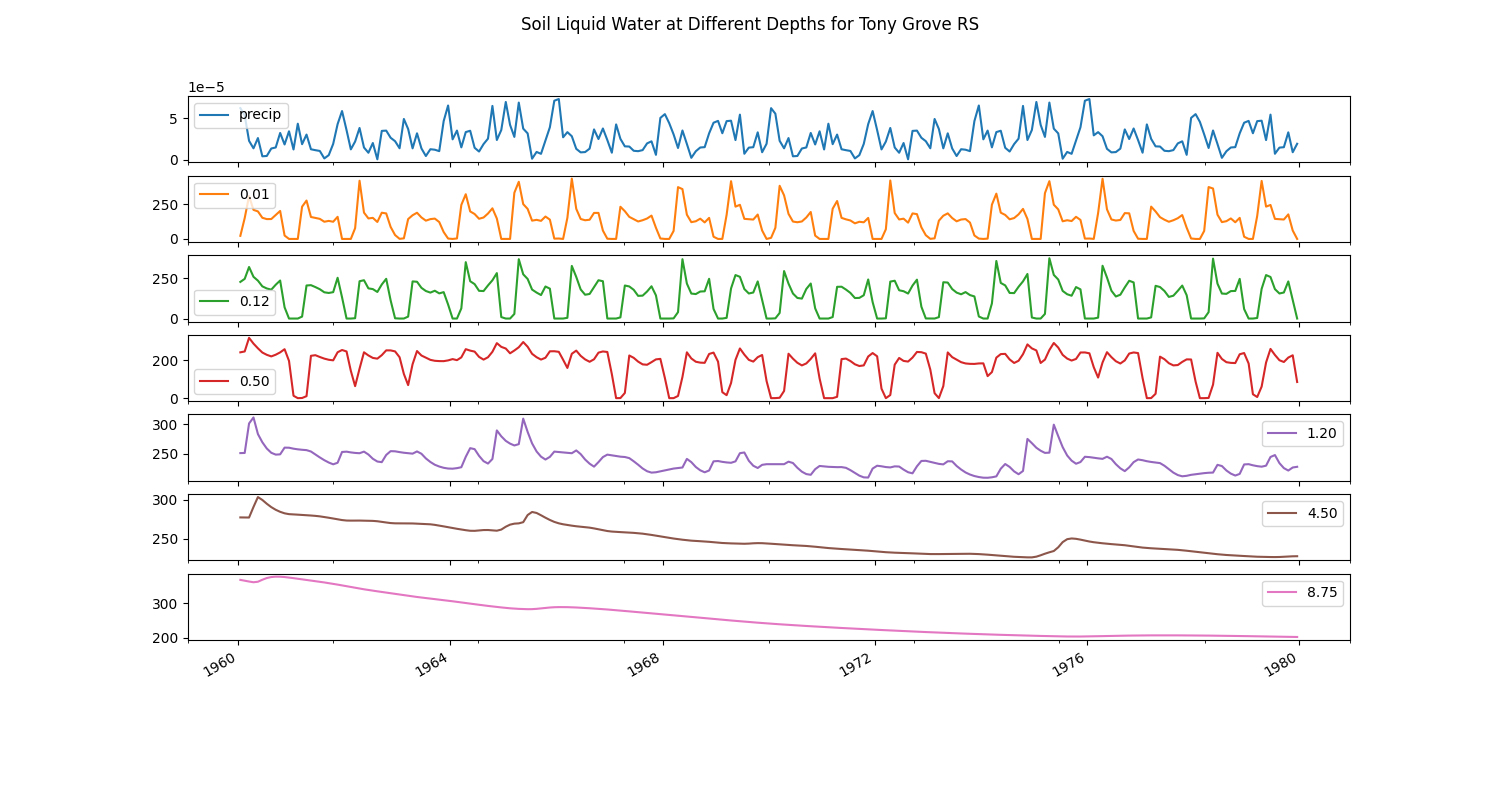

In [30]:
soil_liq[['precip','0.01','0.12','0.50','1.20','4.50','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Liquid Water at Different Depths for ' + snotel_site)